In [1]:
import sys

log_dir = r"/opt/data/private/HFM-MixedFlow/"
sys.path.append(log_dir)  # Add parent directory to system path

from typing import List, Tuple
from demo.utils import *
# from models.TMFPINN_Lite import TMFPINNLite as TMFPINN
save_dir = r"res/04Vasconceles/V_NTK_expr.pth"
from models.TMFPINN2 import TMFPINN
from tqdm import tqdm

from demo.ntk import compute_ntk, get_n_params

In [2]:
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
set_seed()
flag = torch.cuda.is_available()
flag

True

# Step 1. Feature Engineering

In [3]:
log_dir_h = r"../../data/04Vasconceles/res/res_h.mat"
log_dir_u = r"../../data/04Vasconceles/res/res_u.mat"
log_dir_expr = r"../../data/04Vasconceles/Vasconcelos.csv"

from scipy.io import loadmat
res_h0 = loadmat(log_dir_h) #[t,h_pipe]
res_u0 = loadmat(log_dir_u) #[t,u_pipe]

In [4]:
# 如果样本太多，可以适当采样
res_h=res_h0['res_h'][::100]
res_u=res_u0['res_u'][::100]

In [5]:
hmax = res_h[:,1:].max()
umax = res_u[:,1:].max()
hmin = res_h[:,1:].min()
umin = res_u[:,1:].min()
hmax,hmin,umax,umin

(0.3671348438258304, 0.073, 0.3312371414180699, -0.0924101649965235)

In [6]:
import pandas as pd

df = pd.read_csv(log_dir_expr, header=None, skiprows=1)  # 读取文件，跳过第一行（标题行）

tv = df.iloc[:, 0].values  # 第一列
v = df.iloc[:, 1].values   # 第二列
th = df.iloc[:, 2].values  # 第三列
h = df.iloc[:, 3].values   # 第四列

## 1.1 Pipe Parameters

In [7]:
PipeLength = 14.33 # m
FinalTime = 40 # s
Width = 0.094 # m
Diameter = 0.094 # m, the height in Rectangular X-section
Slope = 0.0
Roughness = 0.016 # Manning roughness coefficient
WaveSpeed = 30.0 # m/s

# Ts = 0.01*Diameter
# WaveSpeed=np.sqrt(9.81*np.pi*Diameter*Diameter/4/Ts)
# WaveSpeed

In [8]:
# transform to the Tensor
# w_a_ = ftensor(WaveSpeed, requires_grad=True, device=device)
# D_ = ftensor(Diameter, requires_grad=True, device=device)
# fric_ = ftensor(Roughness, requires_grad=True, device=device)
# S_ = ftensor(Slope, requires_grad=True, device=device)
w_a_ = WaveSpeed
D_ = Diameter
W_ = Width
fric_ = Roughness  
S_ = Slope

## 1.2 Temporal and Spatial info.

In [9]:
MeshNumber = res_h.shape[1]-3 # -1:time -2:BC
TimeNumber = res_h.shape[0]

x_all = np.linspace(0, PipeLength, MeshNumber)
t_all = res_h[:,0]

In [10]:
p99=int(9.9/PipeLength*MeshNumber)
print(p99,MeshNumber)
# obs_index = [p99]
# obs_index = [int(MeshNumber/6)-1,
#              int(MeshNumber/3)-1,
#              int(MeshNumber/2)-1, 
#              int(MeshNumber/3*2)-1,
#              int(MeshNumber/6*5)-1] # 0 and -1 means Boundary Condition
# obs_index = [0,
#              int(MeshNumber/4)-1,
#              int(MeshNumber/2)-1, 
#              int(MeshNumber/4*3)-1,
#              -1] # 0 and -1 means Boundary Condition

# obs_index = [
#              int(MeshNumber/4)-1,
#              int(MeshNumber/2)-1, 
#              p99,
#              ] # 0 and -1 means Boundary Condition
obs_index = [int(MeshNumber/6)-1,
             int(MeshNumber/3)-1,
             int(MeshNumber/2)-1, 
             p99,
             int(MeshNumber/6*5)-1] # 0 and -1 means Boundary Condition

# obs_index = np.arange(0,MeshNumber,1)
# obs_index = [0, int(MeshNumber/2)-1, -1]
print(obs_index, len(obs_index))
t_obs = t_all.copy()
x_obs = np.array([x_all[i] for i in obs_index])

69 101
[15, 32, 49, 69, 83] 5


In [11]:
# ibc_index = [1,-2] #[1,5,-5,-2]
# t_ibc = t_all.copy()
# x_ibc = np.array([x_all[i] for i in ibc_index])
x_ibc = x_all.copy()
t_ibc = [res_h[0,0]]

## 1.3 Load Data

In [12]:
# Xf, Uf, Xobs, _, Xibc, Uibc = load_mat_dataset(
#     res_h[:,1:],res_u[:,1:],
#     x_all,t_all,
#     x_obs,t_obs,
#     x_ibc,t_ibc,
#     obs_index,
#     ibc_index=ibc_index,
#     device=device,
#     flag=1,
# )
Xf, Uf, Xobs, _, Xibc, Uibc = load_mat_dataset(
    res_h[:,1:],res_u[:,1:],
    x_all,t_all,
    x_obs,t_obs,
    x_ibc,t_ibc,
    obs_index,
    device=device,
)

In [13]:
h99=np.interp(t_obs, th, h)
v99=np.interp(t_obs, tv, v)
h1=res_h[:,obs_index[0]]
u1=res_u[:,obs_index[0]]
h2=res_h[:,obs_index[1]]
u2=res_u[:,obs_index[1]]
h3=res_h[:,obs_index[2]]
u3=res_u[:,obs_index[2]]
h5=res_h[:,obs_index[4]]
u5=res_u[:,obs_index[4]]
Uobs_h=np.array([h1,h2,h3,h99,h5]).T
Uobs_u=np.array([u1,u2,u3,v99,u5]).T
Uobs=(Uobs_h,Uobs_u)

In [14]:
Xf[0].shape, Uf[0].shape, Xobs[0].shape, Uobs[0].shape, Xibc[0].shape, Uibc[0].shape

((212, 101), (212, 101), (212, 5), (212, 5), (1, 101), (1, 101))

## 1.4 Load Training Data

In [15]:
Nt = 1000
Nx = 1000
x_train = np.linspace(0, PipeLength, Nx)
t_train = np.linspace(0, FinalTime, Nt)
X_train = (x_train, t_train)

In [16]:
# load training data
Xt_train, Xobs_train, Uobs_train, Xibc_train, Uibc_train = load_mat_training_data(
    X_train,
    Xobs, Uobs, 
    Xibc, Uibc,
    device=device,
)

In [17]:
# transform the height to the alpha
alpha_f, alpha_obs, alpha_ibc = alpha_transform_from_height(Uf,Uobs,Uibc,Height=D_)

# transform to the Tensor
alpha_f_tensor = ftensor(alpha_f, requires_grad=True, device=device).flatten().unsqueeze(1)
alpha_obs_tensor  =  ftensor(alpha_obs, requires_grad=True,device=device).flatten().unsqueeze(1)
alpha_ibc_tensor  =  ftensor(alpha_ibc, requires_grad=True,device=device).flatten().unsqueeze(1)

## 1.5 Max-min Normalization

In [18]:
#  max-min normalization
lb = ftensor([0.0, 0.0], requires_grad=False, device=device)
ub = ftensor([PipeLength, FinalTime], requires_grad=False, device=device)

In [19]:
# load normalized training data
# 因为自动微分中需要对原来的x和t进行求导，所以这里无需对x和t进行归一化，放在PINN内部进行
# 注意，alpha和PINN的归一化范围不同，前者是0到1，后者是-1到1
# Xt_train_norm, Xobs_train_norm, Xic_train_norm = load_mat_normalization_data(
#     X_train, Xobs, Xic,
#     lb, ub,
# )

In [20]:
# 将输入数据从tuple转换为List(torch.Tensor)
Xt_train_tensor= torch.cat([Xt_train[0][0],Xt_train[0][1]],dim=1)
Xobs_train_tensor = torch.cat([Xobs_train[0][0],Xobs_train[0][1]],dim=1)
Xibc_train_tensor = torch.cat([Xibc_train[0][0],Xibc_train[0][1]],dim=1)

# Step 2. Model Training

## 2.1 Hyperparameters

In [21]:
h_max = ftensor(hmax, requires_grad=True, device=device)
h_min = ftensor(hmin, requires_grad=True, device=device)
u_max = ftensor(umax, requires_grad=True, device=device)
u_min = ftensor(umin, requires_grad=True, device=device)

In [22]:
# 两者最好一样，否则反向传播时会不收敛，误差计算的梯度不一样
layers = [2,512,512,512,512, 2]
layers_alpha = [2,512,512,512,512, 1]

# layers = [2,64,64,64,64,64,64,64,64,2]
# layers_alpha = [2,64,64,64,64,64,64,64,64,1]

## 2.2 Create Model

In [23]:
model = TMFPINN(layers, layers_alpha, lb, ub, device=device).to(device)

In [24]:
# Define optimizer
opt = torch.optim.Adam(model.parameters(), lr=1e-4)
# opt2 = torch.optim.LBFGS(model.parameters(), lr=1.0, line_search_fn='strong_wolfe')
# optimizers: using the same settings
# opt = torch.optim.Adam(
#     model.parameters(),          # Parameters to optimize
#     lr=0.001,                    # Learning rate
#     betas=(0.9, 0.999),          # Coefficients for computing running averages of gradient and its square
#     eps=1e-8,                    # Term added to improve numerical stability
#     weight_decay=0               # Weight decay (L2 penalty)
# )
opt2 = torch.optim.LBFGS(
    model.parameters(),
    lr=1.0,
    max_iter=50000,
    max_eval=50000,
    history_size=50,
    tolerance_grad=1e-10,
    tolerance_change=0.5 * np.finfo(float).eps,
    line_search_fn="strong_wolfe"  # can be "strong_wolfe" or "None"
)

# loss function
loss_fn = torch.nn.MSELoss()

# learning rate scheduler
lr_scheduler = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.9)
lr_scheduler2 = torch.optim.lr_scheduler.ExponentialLR(opt2, gamma=0.9)

## 2.3 Loss function and Training

In [25]:
epochs_Adam = 20000-1 # 800000
epochs_LBFGS = 10
ntks_Adam = 1000
ntks_LBFGS = 50

W_u=1.0
W_alpha=1.0
# Ratio = np.mean(np.abs(Uf[0]))/np.mean(np.abs(Uf[1]))
# W_u = 1.0 if Ratio<1 else Ratio
# W_alpha = len(alpha_obs_tensor)
# print(W_u, W_alpha)

losses = []

In [26]:
# NTK 2025-1-14
n_params_total = get_n_params(model)
n_params_alphaDNN = get_n_params(model.AlphaDNN)
n_params = n_params_total-n_params_alphaDNN 

print(model)
print(get_n_params(model))
# print(n_params,get_n_params(model.PINN))
print(n_params_alphaDNN)

TMFPINN(
  (AlphaDNN): Sequential(
    (layer_0): Linear(in_features=2, out_features=512, bias=True)
    (activation_0): Sigmoid()
    (layer_1): Linear(in_features=512, out_features=512, bias=True)
    (activation_1): Sigmoid()
    (layer_2): Linear(in_features=512, out_features=512, bias=True)
    (activation_2): Sigmoid()
    (layer_3): Linear(in_features=512, out_features=512, bias=True)
    (activation_3): Sigmoid()
    (layer_4): Linear(in_features=512, out_features=1, bias=True)
  )
  (weights): ParameterList(
      (0): Parameter containing: [torch.float32 of size 2x512 (cuda:1)]
      (1): Parameter containing: [torch.float32 of size 512x512 (cuda:1)]
      (2): Parameter containing: [torch.float32 of size 512x512 (cuda:1)]
      (3): Parameter containing: [torch.float32 of size 512x512 (cuda:1)]
      (4): Parameter containing: [torch.float32 of size 1024x2 (cuda:1)]
  )
  (biases): ParameterList(
      (0): Parameter containing: [torch.float32 of size 1x512 (cuda:1)]
      (

In [27]:
# kernel_size = 2 * len(Xibc_train_tensor[:,0:1])
kernel_size = 100
# kernel_size = len(Xt_train_tensor[:,0:1])/2
D1 = kernel_size
# D2 = len(Xibc_train_tensor[:,0:1]) # 0 -> 0.1 ... 0.99 ->1 ic  3 points
# D3 = len(Xobs_train_tensor[:,0:1]) # 0 -> ... -> 0 bc  2 points
D2 = kernel_size
D3 = kernel_size
print(D1,D2,D3)
# initialize the kernel
loss_track = []
w1, w2, w3 = 1, 1, 1

100 100 100


In [28]:
for ep in range(epochs_Adam):
    
    if ep % ntks_Adam == 0:
        J1 = torch.zeros((D1, n_params)) # 200 * 527361的零矩阵
        J2 = torch.zeros((D2, n_params)) # 101 * 527361的零矩阵
        J3 = torch.zeros((D3, n_params)) # 101 * 527361的零矩阵

        # sample a batch of data,从res中随机选取kernel_size个数据
        # 200个数据， res有10201个数据
        d1_batch_ind = np.random.choice(len(Xt_train_tensor[:,0:1]), kernel_size, replace=False)
        d2_batch_ind = np.random.choice(len(Xibc_train_tensor[:,0:1]), kernel_size, replace=False)
        d3_batch_ind = np.random.choice(len(Xobs_train_tensor[:,0:1]), kernel_size, replace=False)

        Xt_train_tensor_NTK = Xt_train_tensor[d1_batch_ind]
        Xibc_train_tensor_NTK = Xibc_train_tensor[d2_batch_ind]
        Xobs_train_tensor_NTK = Xobs_train_tensor[d3_batch_ind]
        
        pred_res,_ = model(Xt_train_tensor_NTK)
        pred_OBS,_ = model(Xobs_train_tensor_NTK)
        pred_IBC,_ = model(Xibc_train_tensor_NTK)

        for j in range(len(J1)):
            model.zero_grad()
            pred_res[j][0].backward(retain_graph=True)
            pred_res[j][1].backward(retain_graph=True)
            J1[j, :] = torch.cat([p.grad.view(-1) for p in model.parameters() if p.grad is not None])

        for j in range(len(J2)):
            model.zero_grad()
            pred_IBC[j][0].backward(retain_graph=True)
            pred_IBC[j][1].backward(retain_graph=True)
            J2[j, :] = torch.cat([p.grad.view(-1) for p in model.parameters() if p.grad is not None])

        for j in range(len(J3)):
            model.zero_grad()
            pred_OBS[j][0].backward(retain_graph=True)
            pred_OBS[j][1].backward(retain_graph=True)
            J3[j, :] = torch.cat([p.grad.view(-1) for p in model.parameters() if p.grad is not None])

        K1 = torch.trace(compute_ntk(J1, J1))
        K2 = torch.trace(compute_ntk(J2, J2))
        K3 = torch.trace(compute_ntk(J3, J3))
        
        K = K1+K2+K3

        w1 = K.item() / K1.item()
        w2 = K.item() / K2.item()
        w3 = K.item() / K3.item()
        
    # prediction
    f_preds = f_Circle(model, Xt_train_tensor, fric_, D_, W_, w_a_, S_, h_min, h_max, u_min, u_max, device=device)
    Uobs_preds, alpha_obs_preds = U(model, Xobs_train_tensor, h_min, h_max, u_min, u_max)
    Uibc_preds, alpha_ibc_preds = U(model, Xibc_train_tensor, h_min, h_max, u_min, u_max)

    # losses
    losses_ = []
    
    mse_obs_h = loss_fn(Uobs_train[0][0], Uobs_preds[0])
    mes_obs_alpha = loss_fn(alpha_obs_tensor, alpha_obs_preds)
    # mse_obs = mse_obs_h + W_alpha * mes_obs_alpha
    mse_obs_u = loss_fn(Uobs_train[0][1], Uobs_preds[1])
    mse_obs = mse_obs_h + W_u * mse_obs_u + W_alpha * mes_obs_alpha
    
    mse_ibc_h = loss_fn(Uibc_train[0][0], Uibc_preds[0])
    mes_ibc_alpha = loss_fn(alpha_ibc_tensor, alpha_ibc_preds)
    # mse_ic = mse_ic_h + W_alpha * mes_ic_alpha
    mse_ibc_u = loss_fn(Uibc_train[0][1], Uibc_preds[1])
    mse_ibc = mse_ibc_h + W_u * mse_ibc_u + W_alpha * mes_ibc_alpha
    
    mse_f = sum(
            loss_fn(torch.zeros_like(pred_tensor), pred_tensor)
            for pred_tensor in f_preds
        )
    
    loss_obs = w3 * mse_obs
    losses_.append(loss_obs)
    
    loss_ibc = w2 * mse_ibc
    losses_.append(loss_ibc)
    
    loss_f = w1 * mse_f
    losses_.append(loss_f)
    
    loss_track.append([loss_f.item(), loss_ibc.item(), loss_obs.item()])

    total_loss = loss_obs + loss_ibc + loss_f
    losses_.append(total_loss)
    
    # optimizer
    opt.zero_grad()
    loss = sum(losses_)
    
    # back-propagation
    loss.backward()
    opt.step()
    if (ep + 1) % 1000 == 0:
        lr_scheduler.step()
    losses.append(list(map(lambda x: x.item(), losses_)))
    
    if (ep + 1) % 1000 == 0:
        with torch.no_grad():
            # load test data
            Xf_test, Uf_test=[], []
            x_f_test = ftensor(Xf[0], requires_grad=True, device=device)
            t_f_test = ftensor(Xf[1], requires_grad=True, device=device)
            Xf_test.append((x_f_test.flatten().unsqueeze(1), t_f_test.flatten().unsqueeze(1)))

            h_f_test = ftensor(Uf[0], requires_grad=True, device=device)
            u_f_test = ftensor(Uf[1], requires_grad=True, device=device)
            Uf_test.append((h_f_test.flatten().unsqueeze(1), u_f_test.flatten().unsqueeze(1)))

            # 转为normalization data
            X_test_tensor= torch.cat([Xf_test[0][0],Xf_test[0][1]],dim=1)
            Uf_preds,_ = U(model, X_test_tensor, h_min, h_max, u_min, u_max)
            # 转换为 NumPy 数组
            h_preds_np = Uf_preds[0].cpu().detach().numpy()
            u_preds_np = Uf_preds[1].cpu().detach().numpy()
            
            h_test_np = Uf_test[0][0].cpu().detach().numpy()
            u_test_np = Uf_test[0][1].cpu().detach().numpy()
    
            # 计算决定系数 (R²)：最佳值为1.0，范围为(-∞, 1.0]
            ss_total_water_level = ((h_test_np - h_test_np.mean()) ** 2).sum()
            ss_res_water_level = ((h_test_np - h_preds_np) ** 2).sum()
            r2_water_level = 1 - (ss_res_water_level / ss_total_water_level)
            
            ss_total_velocity = ((u_test_np - u_test_np.mean()) ** 2).sum()
            ss_res_velocity = ((u_test_np - u_preds_np) ** 2).sum()
            r2_velocity = 1 - (ss_res_velocity / ss_total_velocity)
            
            # print loss
            log = f"Epoch {ep + 1:4d} loss_total {losses[-1][-1]:12,.6f}"
            # print r2
            log += f" r2_water_level {r2_water_level:12,.6f}"
            log += f" r2_velocity {r2_velocity:12,.6f}"
            # print NTK
            log += 'NTK weight: w_res: {:4f} w_ibc: {:4f}, w_obs: {:4f}'.format(w1, w2, w3)
        
            print(log)

Epoch 1000 loss_total     0.061977 r2_water_level     0.971582 r2_velocity     0.796083NTK weight: w_res: 2.991778 w_ibc: 2.999719, w_obs: 3.008551
Epoch 2000 loss_total     0.033858 r2_water_level     0.977238 r2_velocity     0.807445NTK weight: w_res: 2.985828 w_ibc: 2.990811, w_obs: 3.023642
Epoch 3000 loss_total     0.025257 r2_water_level     0.978808 r2_velocity     0.832076NTK weight: w_res: 3.035018 w_ibc: 2.867579, w_obs: 3.107653
Epoch 4000 loss_total     0.021154 r2_water_level     0.980997 r2_velocity     0.857404NTK weight: w_res: 2.970558 w_ibc: 2.959915, w_obs: 3.072053
Epoch 5000 loss_total     0.018276 r2_water_level     0.981139 r2_velocity     0.866055NTK weight: w_res: 2.997202 w_ibc: 2.971960, w_obs: 3.031430
Epoch 6000 loss_total     0.016826 r2_water_level     0.981918 r2_velocity     0.871456NTK weight: w_res: 2.959059 w_ibc: 3.023299, w_obs: 3.018501
Epoch 7000 loss_total     0.015321 r2_water_level     0.982545 r2_velocity     0.875648NTK weight: w_res: 2.9738

In [29]:
# %% L-BFGS-B
for i in tqdm(range(epochs_LBFGS)):
    if i % ntks_LBFGS == 0 and i!=0:
        J1 = torch.zeros((D1, n_params)) # 200 * 527361的零矩阵
        J2 = torch.zeros((D2, n_params)) # 101 * 527361的零矩阵
        J3 = torch.zeros((D3, n_params)) # 101 * 527361的零矩阵

        # sample a batch of data,从res中随机选取kernel_size个数据
        # 200个数据， res有10201个数据
        d1_batch_ind = np.random.choice(len(Xt_train_tensor[:,0:1]), kernel_size, replace=False)
        d2_batch_ind = np.random.choice(len(Xibc_train_tensor[:,0:1]), kernel_size, replace=False)
        d3_batch_ind = np.random.choice(len(Xobs_train_tensor[:,0:1]), kernel_size, replace=False)

        Xt_train_tensor_NTK = Xt_train_tensor[d1_batch_ind]
        Xibc_train_tensor_NTK = Xibc_train_tensor[d2_batch_ind]
        Xobs_train_tensor_NTK = Xobs_train_tensor[d3_batch_ind]
        
        pred_res,_ = model(Xt_train_tensor_NTK)
        pred_OBS,_ = model(Xobs_train_tensor_NTK)
        pred_IBC,_ = model(Xibc_train_tensor_NTK)

        for j in range(len(J1)):
            model.zero_grad()
            pred_res[j][0].backward(retain_graph=True)
            pred_res[j][1].backward(retain_graph=True)
            J1[j, :] = torch.cat([p.grad.view(-1) for p in model.parameters() if p.grad is not None])

        for j in range(len(J2)):
            model.zero_grad()
            pred_IBC[j][0].backward(retain_graph=True)
            pred_IBC[j][1].backward(retain_graph=True)
            J2[j, :] = torch.cat([p.grad.view(-1) for p in model.parameters() if p.grad is not None])

        for j in range(len(J3)):
            model.zero_grad()
            pred_OBS[j][0].backward(retain_graph=True)
            pred_OBS[j][1].backward(retain_graph=True)
            J3[j, :] = torch.cat([p.grad.view(-1) for p in model.parameters() if p.grad is not None])

        K1 = torch.trace(compute_ntk(J1, J1))
        K2 = torch.trace(compute_ntk(J2, J2))
        K3 = torch.trace(compute_ntk(J3, J3))
        
        K = K1+K2+K3

        w1 = K.item() / K1.item()
        w2 = K.item() / K2.item()
        w3 = K.item() / K3.item()
        
    def closure():
        # prediction
        f_preds = f_Circle(model, Xt_train_tensor, fric_, D_, W_, w_a_, S_, h_min, h_max, u_min, u_max,device=device)
        Uobs_preds, alpha_obs_preds = U(model, Xobs_train_tensor, h_min, h_max, u_min, u_max)
        Uibc_preds, alpha_ibc_preds = U(model, Xibc_train_tensor, h_min, h_max, u_min, u_max)

        # losses
        losses_ = []
        
        mse_obs_h = loss_fn(Uobs_train[0][0], Uobs_preds[0])
        mes_obs_alpha = loss_fn(alpha_obs_tensor, alpha_obs_preds)
        # mse_obs = mse_obs_h + W_alpha * mes_obs_alpha
        mse_obs_u = loss_fn(Uobs_train[0][1], Uobs_preds[1])
        mse_obs = mse_obs_h + W_u * mse_obs_u + W_alpha * mes_obs_alpha
        
        mse_ibc_h = loss_fn(Uibc_train[0][0], Uibc_preds[0])
        mes_ibc_alpha = loss_fn(alpha_ibc_tensor, alpha_ibc_preds)
        # mse_ic = mse_ic_h + W_alpha * mes_ic_alpha
        mse_ibc_u = loss_fn(Uibc_train[0][1], Uibc_preds[1])
        mse_ibc = mse_ibc_h + W_u * mse_ibc_u + W_alpha * mes_ibc_alpha
        
        mse_f = sum(
                loss_fn(torch.zeros_like(pred_tensor), pred_tensor)
                for pred_tensor in f_preds
            )
        
        loss_obs = w3 * mse_obs
        losses_.append(loss_obs)
        
        loss_ibc = w2 * mse_ibc
        losses_.append(loss_ibc)
        
        loss_f = w1 * mse_f
        losses_.append(loss_f)
        
        loss_track.append([loss_f.item(), loss_ibc.item(), loss_obs.item()])

        total_loss = loss_obs + loss_ibc + loss_f
        losses_.append(total_loss)
        
        opt2.zero_grad()
        
        loss = sum(losses_)
        loss.backward(retain_graph=True)
        
        # store losses
        losses.append(list(map(lambda x: x.item(), losses_)))
        return loss

    opt2.step(closure)
    if (i + 1) % 100 == 0:
        lr_scheduler2.step()

100%|██████████| 10/10 [04:43<00:00, 28.35s/it]


# Step 3. Post Pocessing

## 3.1 Plot Loss Curve

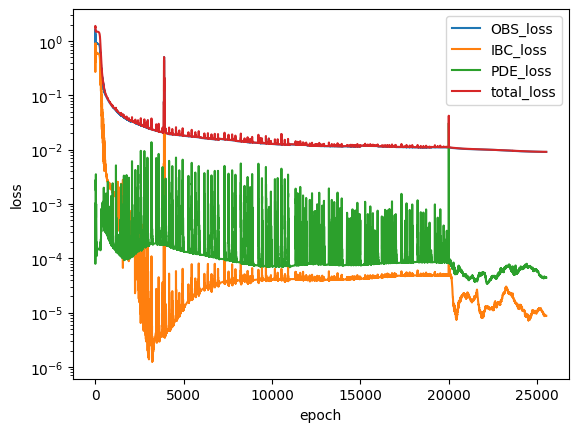

In [30]:
if_log = True # 指数坐标
lossnames = ["OBS_loss", "IBC_loss", "PDE_loss", "total_loss"]
for loss, name in zip(np.asarray(losses).T, lossnames):
    plt.plot(np.arange(1, len(loss) + 1), loss, label=name)
plt.xlabel("epoch")
plt.ylabel("loss")
if if_log: 
    plt.yscale("log")
plt.legend(loc="upper right")
# plt.savefig(plot_path)

In [31]:
loss_file_name=r"../../UA/UA3/"
# 保存 loss 数据到 npy 文件
for loss, name in zip(np.asarray(losses).T, lossnames):
    np.save(loss_file_name+f"V_{name}.npy", loss)  # 保存为 .npy 文件
    # plt.plot(epochs, loss, label=name)


## 3.2 Plot results

In [32]:
f_preds = f_Circle(model, Xt_train_tensor, fric_, D_, W_, w_a_, S_, h_min, h_max, u_min, u_max, device=device)
Uobs_preds, alpha_obs_preds = U(model, Xobs_train_tensor, h_min, h_max, u_min, u_max)
Uibc_preds, alpha_ibc_preds = U(model, Xibc_train_tensor, h_min, h_max, u_min, u_max)

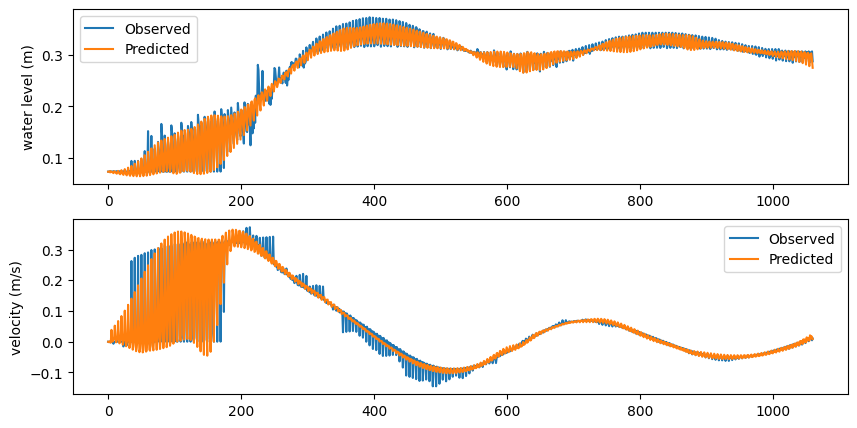

In [33]:
# 监测点：obs_idx
with torch.no_grad():
    plt.figure(1,figsize=(10,5))
    plt.subplot(2, 1, 1)
    plt.plot(Uobs_train[0][0].cpu().detach().numpy(), label='Observed')
    plt.plot(Uobs_preds[0].cpu().detach().numpy(), label='Predicted')
    plt.legend()  # Add legend to the first figure
    #plt.xlabel('Time steps')  # Customize as needed
    plt.ylabel('water level (m)')  # Customize as needed
    
    plt.subplot(2, 1, 2)
    plt.plot(Uobs_train[0][1].cpu().detach().numpy(), label='Observed')
    plt.plot(Uobs_preds[1].cpu().detach().numpy(), label='Predicted')
    plt.legend()  # Add legend to the first figure
    #plt.xlabel('epochs')  # Customize as needed
    plt.ylabel('velocity (m/s)')  # Customize as needed

    #plt.savefig(osp.join(log_dir, 'wdsxpinn_res/obs.png'))

In [34]:
# load test data
Xf_test, Uf_test=[], []
x_f_test = ftensor(Xf[0], requires_grad=True, device=device)
t_f_test = ftensor(Xf[1], requires_grad=True, device=device)
Xf_test.append((x_f_test.flatten().unsqueeze(1), t_f_test.flatten().unsqueeze(1)))

h_f_test = ftensor(Uf[0], requires_grad=True, device=device)
u_f_test = ftensor(Uf[1], requires_grad=True, device=device)
Uf_test.append((h_f_test.flatten().unsqueeze(1), u_f_test.flatten().unsqueeze(1)))

# 转为normalization data
X_test_tensor= torch.cat([Xf_test[0][0],Xf_test[0][1]],dim=1)

Uf_preds,alpha_f_preds = U(model, X_test_tensor, h_min, h_max, u_min, u_max)

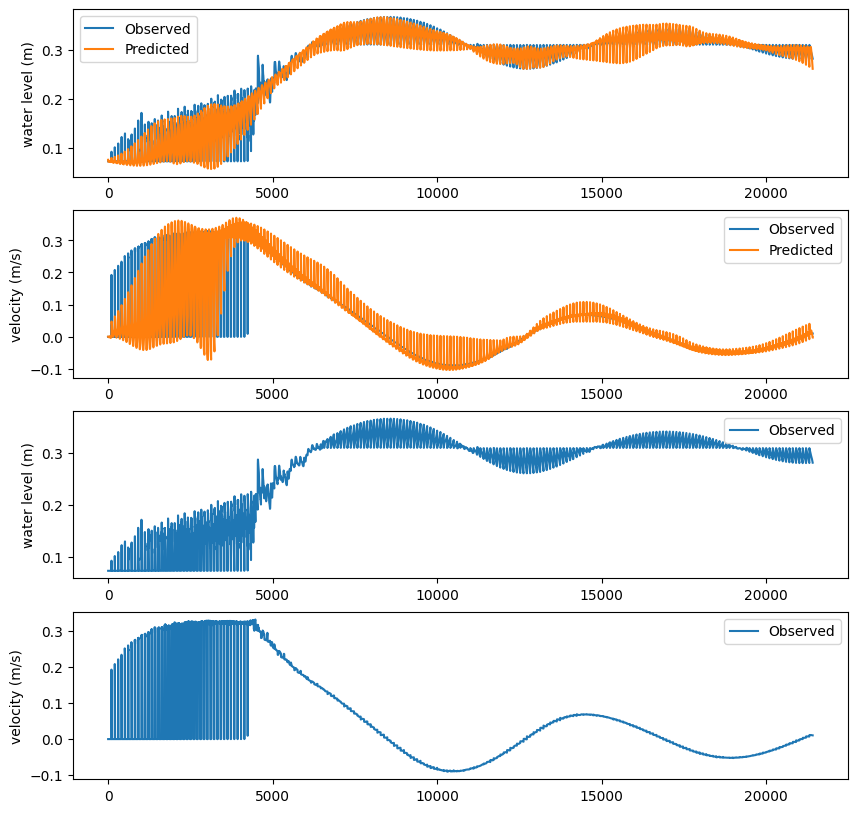

In [35]:
# 全局图
with torch.no_grad():
    plt.figure(3,figsize=(10,10))
    plt.subplot(4, 1, 1)
    plt.plot(Uf_test[0][0].cpu().detach().numpy(), label='Observed')
    plt.plot(Uf_preds[0].cpu().detach().numpy(), label='Predicted')
    plt.legend()  # Add legend to the first figure
    #plt.xlabel('Time steps')  # Customize as needed
    plt.ylabel('water level (m)')  # Customize as needed
    
    plt.subplot(4, 1, 2)
    plt.plot(Uf_test[0][1].cpu().detach().numpy(), label='Observed')
    plt.plot(Uf_preds[1].cpu().detach().numpy(), label='Predicted')
    plt.legend()  # Add legend to the first figure
    #plt.xlabel('epochs')  # Customize as needed
    plt.ylabel('velocity (m/s)')  # Customize as needed
    
    plt.subplot(4, 1, 3)
    plt.plot(Uf_test[0][0].cpu().detach().numpy(), label='Observed')
    # plt.plot(Uf_preds[0].cpu().detach().numpy(), label='Predicted')
    plt.legend()  # Add legend to the first figure
    #plt.xlabel('Time steps')  # Customize as needed
    plt.ylabel('water level (m)')  # Customize as needed
    
    plt.subplot(4, 1, 4)
    plt.plot(Uf_test[0][1].cpu().detach().numpy(), label='Observed')
    # plt.plot(Uf_preds[1].cpu().detach().numpy(), label='Predicted')
    plt.legend()  # Add legend to the first figure
    #plt.xlabel('epochs')  # Customize as needed
    plt.ylabel('velocity (m/s)')  # Customize as needed

In [36]:
# 从展平图中恢复
h_test = Uf_test[0][0].cpu().detach().numpy()
u_test = Uf_test[0][1].cpu().detach().numpy()
h_pred2 = Uf_preds[0].cpu().detach().numpy()
u_pred2 = Uf_preds[1].cpu().detach().numpy()

row, column= Uf[0].shape[0], Uf[0].shape[1]

h_test = h_test.reshape(row, column)
u_test = u_test.reshape(row, column)
h_pred2 = h_pred2.reshape(row, column)
u_pred2 = u_pred2.reshape(row, column)

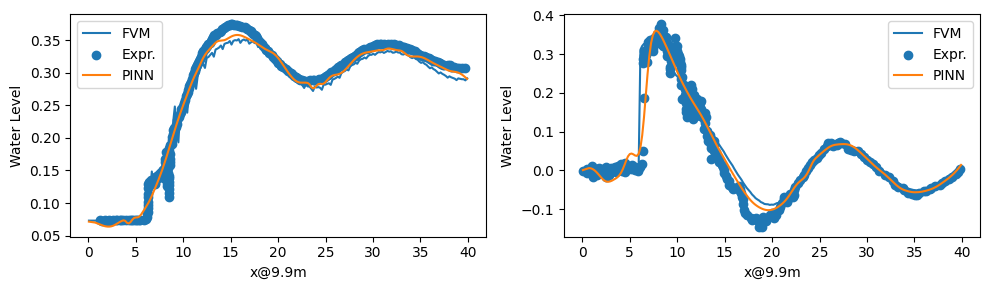

In [37]:
# 实验数据对比图
with torch.no_grad():
    plt.figure(20,figsize=(10,3))
    plt.subplot(1, 2, 1)
    plt.plot(t_all,h_test[:,p99],label='FVM')
    plt.scatter(th,h,label='Expr.')
    plt.plot(t_all,h_pred2[:,p99],label='PINN')
    plt.xlabel('x@9.9m')  # Customize as needed
    plt.ylabel('Water Level')  # Customize as needed
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(t_all,u_test[:,p99],label='FVM')
    plt.scatter(tv,v,label='Expr.')
    plt.plot(t_all,u_pred2[:,p99],label='PINN')
    plt.xlabel('x@9.9m')  # Customize as needed
    plt.ylabel('Water Level')  # Customize as needed
    plt.legend()
    
    
    plt.tight_layout()

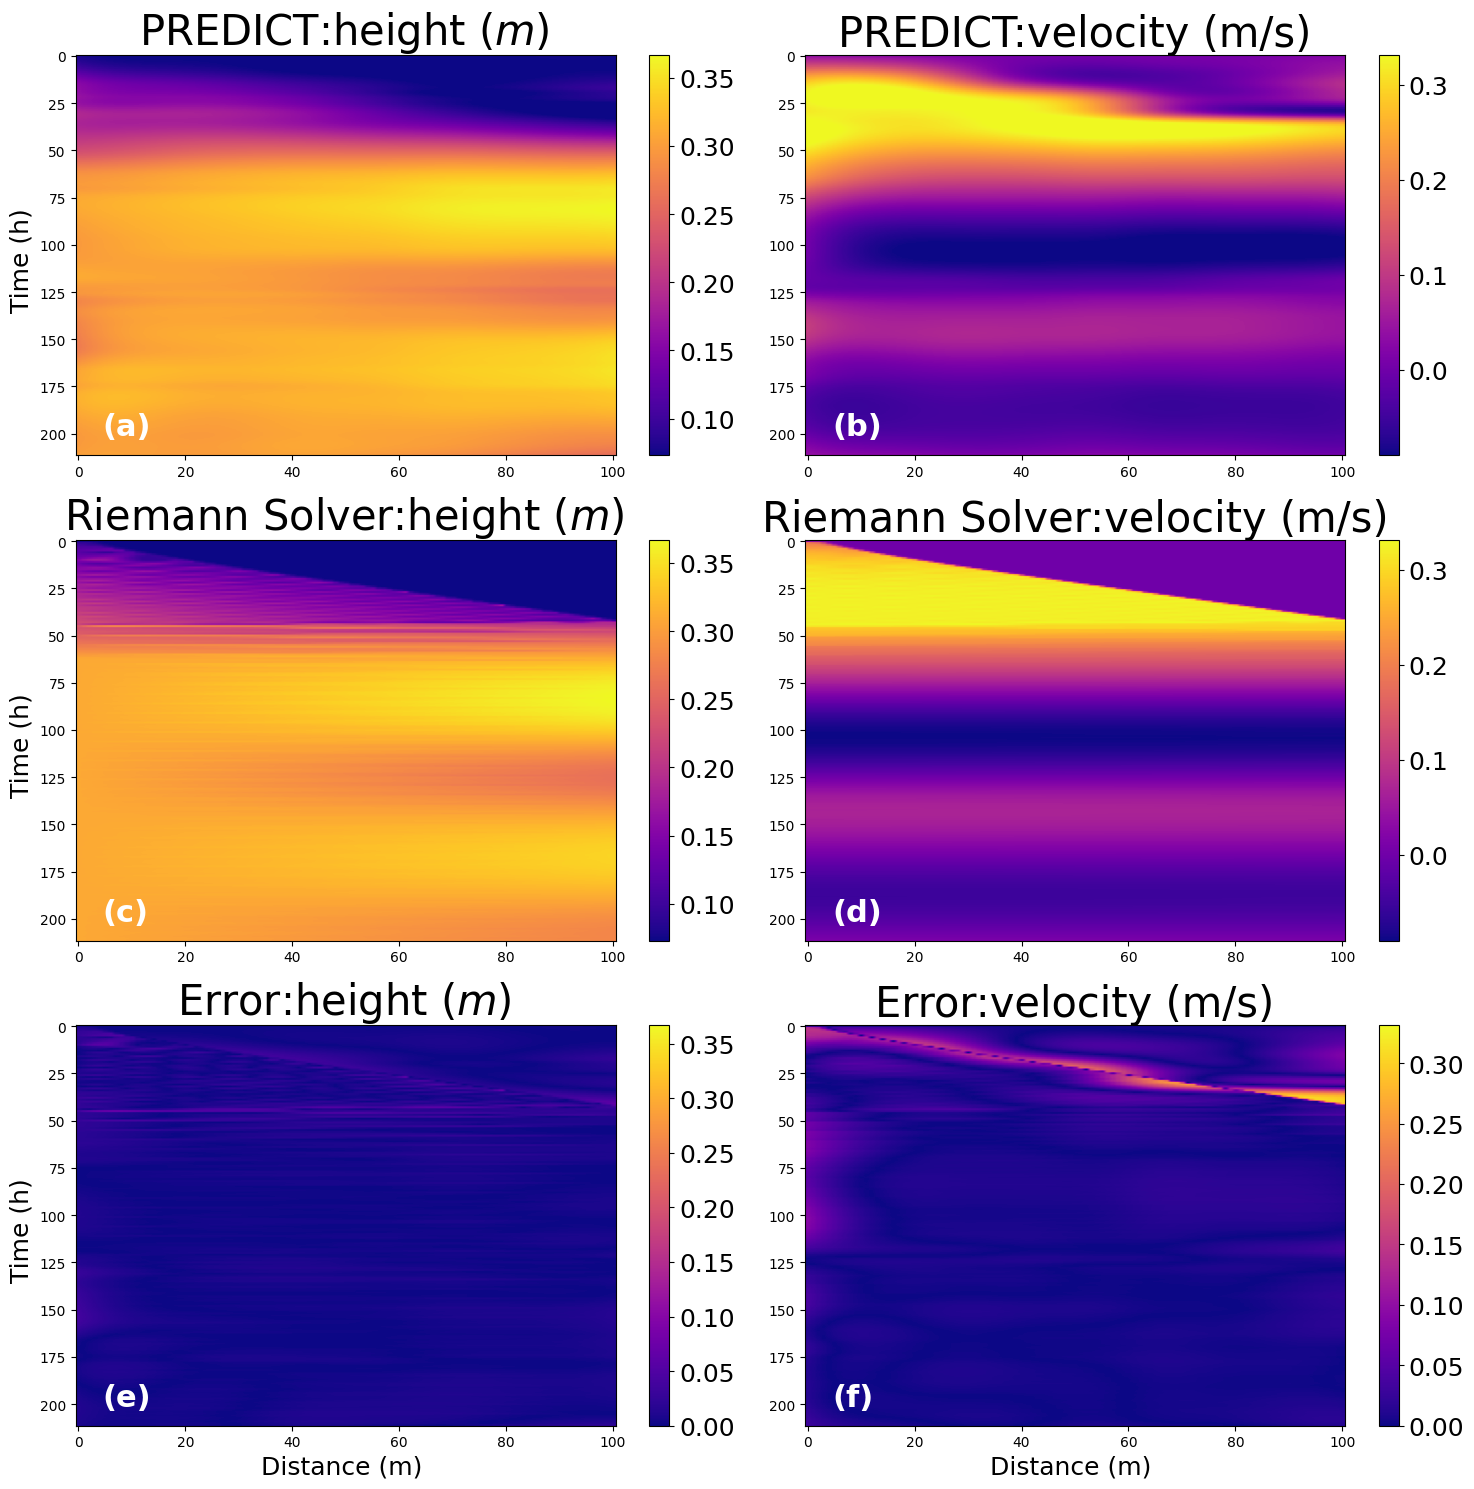

In [38]:
# 全局图2
with torch.no_grad():
    fig, axs = plt.subplots(3, 2, figsize=(15, 15))
    
    variables = [('height $(m)$ ', h_pred2, h_test), ('velocity (m/s)', u_pred2, u_test)]

    labels = ['(a)', '(c)', '(e)', '(b)', '(d)', '(f)']

    vmin=[h_test.min(),h_test.min(),0,u_test.min(),u_test.min(),0]
    vmax=[h_test.max(),h_test.max(),h_test.max(),u_test.max(),u_test.max(),u_test.max()]
    for j, (variable, pred, test) in enumerate(variables):
        titles = [f'PREDICT:{variable}', f'Riemann Solver:{variable}', f'Error:{variable}']
        images = [pred, test, np.abs(test - pred)]

        for i, ax in enumerate(axs[:, j]):
            im = ax.imshow(images[i], aspect='auto', cmap='plasma',vmin=vmin[i + j * 3], vmax=vmax[i + j * 3])
            ax.set_title(titles[i], fontsize=30)
            cbar = plt.colorbar(im, ax=ax, orientation='vertical')
            cbar.ax.tick_params(labelsize=18)  #

            if i == 2:
                ax.set_xlabel('Distance (m) ', fontsize=18)
            if j == 0:
                ax.set_ylabel('Time (h) ', fontsize=18)

            # ax.set_xticks([0, 50, 100, 150, 200, 250], [0, 100,200,300,400,500], fontsize=18)
            # ax.set_yticks([0, 100, 200, 300,400,500,600], [0, 1, 2, 3,4,5,6], fontsize=18)
            ax.text(0.05, 0.05, labels[i + j * 3], transform=ax.transAxes, fontsize=22, weight='bold', color='white')

    plt.tight_layout()
    # plt.savefig(path, dpi=500, bbox_inches='tight')  # 会裁掉多余的白边

In [39]:
# 将alpha从战平图中恢复
alpha_row,alpha_column = alpha_f.shape[0],alpha_f.shape[1]
alpha_f_preds= alpha_f_preds.cpu().detach().numpy().reshape(alpha_row,alpha_column)
alpha_f.shape,alpha_f_preds.shape

((212, 101), (212, 101))

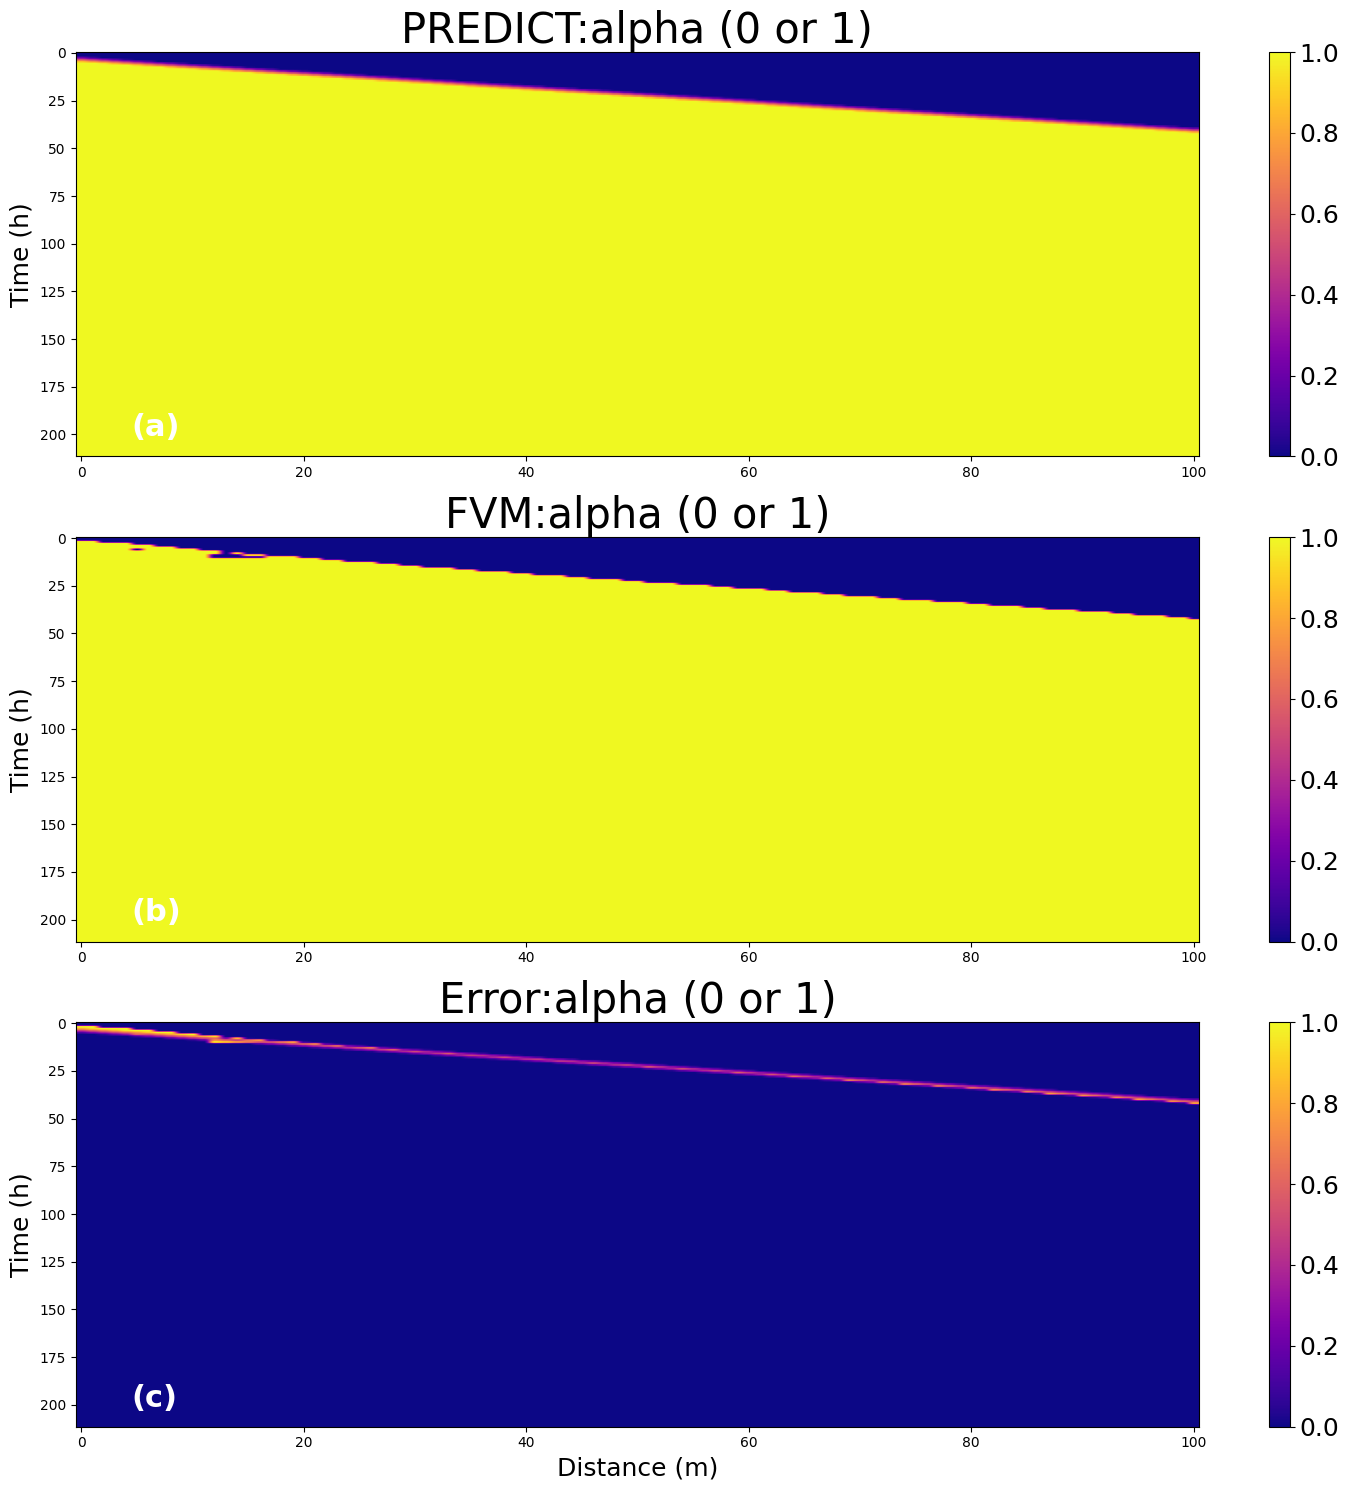

In [40]:
# 绘制alpha图
with torch.no_grad():
    fig, axs = plt.subplots(3, 1, figsize=(15, 15))  # 3行1列布局
    
    variables = [('alpha (0 or 1)', alpha_f_preds, alpha_f)]  # 假设你已经定义了alpha_f_preds和alpha_f

    labels = ['(a)', '(b)', '(c)']

    for j, (variable, pred, test) in enumerate(variables):
        titles = [f'PREDICT:{variable}', f'FVM:{variable}', f'Error:{variable}']
        images = [pred, test, np.abs(test - pred)]

        for i, ax in enumerate(axs):  # axs 是一个1D数组，直接遍历
            im = ax.imshow(images[i], aspect='auto', cmap='plasma', vmin=0, vmax=1)
            ax.set_title(titles[i], fontsize=30)
            cbar = plt.colorbar(im, ax=ax, orientation='vertical')
            cbar.ax.tick_params(labelsize=18)  # 设置颜色条的字体大小

            if i == 2:  # 在误差图像上设置X轴标签
                ax.set_xlabel('Distance (m)', fontsize=18)
            if j == 0:  # 在第一个图像上设置Y轴标签
                ax.set_ylabel('Time (h)', fontsize=18)

            # 设置子图的标签
            ax.text(0.05, 0.05, labels[i + j * 3], transform=ax.transAxes, fontsize=22, weight='bold', color='white')

    plt.tight_layout()  # 自适应布局，避免标签重叠
    # plt.savefig(path, dpi=500, bbox_inches='tight')  # 如果需要保存图像

## 3.3 Evaluation and Save Model

In [41]:
with torch.no_grad():
    hobs_preds_np = Uobs_preds[0].cpu().detach().numpy()
    uobs_preds_np = Uobs_preds[1].cpu().detach().numpy()

    hobs_test_np = Uobs_train[0][0].cpu().detach().numpy()
    uobs_test_np = Uobs_train[0][1].cpu().detach().numpy()

    # 计算均方误差 (MSE)：最佳值为0.0，范围为[0, +∞)
    mse_water_level = ((hobs_test_np - hobs_preds_np) ** 2).mean()
    mse_velocity = ((uobs_test_np - uobs_preds_np) ** 2).mean()

    print(f"Obs:")
    print(f"    Water level: MSE: {mse_water_level:.6f}")
    print(f"    Velocity:    MSE: {mse_velocity:.6f}")

Obs:
    Water level: MSE: 0.000081
    Velocity:    MSE: 0.000499


In [42]:
import numpy as np

epsilon = 1e-8  # 避免分母为零
with torch.no_grad():
    # 转换为 NumPy 数组
    h_preds_np = Uf_preds[0].cpu().detach().numpy()
    u_preds_np = Uf_preds[1].cpu().detach().numpy()
    
    h_test_np = Uf_test[0][0].cpu().detach().numpy()
    u_test_np = Uf_test[0][1].cpu().detach().numpy()
    
    # 计算均方误差 (MSE)：最佳值为0.0，范围为[0, +∞)
    mse_water_level = ((h_test_np - h_preds_np) ** 2).mean()
    mse_velocity = ((u_test_np - u_preds_np) ** 2).mean()
    
    # 计算均方根误差 (RMSE)：最佳值为0.0，范围为[0, +∞)
    rmse_water_level = np.sqrt(mse_water_level)
    rmse_velocity = np.sqrt(mse_velocity)
    
    # 计算平均绝对误差 (MAE)：最佳值为0.0，范围为[0, +∞)
    mae_water_level = abs(h_test_np - h_preds_np).mean()
    mae_velocity = abs(u_test_np - u_preds_np).mean()
    
    # 计算平均绝对百分比误差 (MAPE)：最佳值为0.0，范围为[0, +∞)
    mape_water_level = (abs(h_test_np - h_preds_np) / (abs(h_test_np) + epsilon)).mean() * 100
    mape_velocity = (abs(u_test_np - u_preds_np) / (abs(u_test_np) + epsilon)).mean() * 100
    
    # 计算对称平均绝对百分比误差 (SMAPE)：最佳值为0.0，范围为[0, +∞)
    smape_water_level = (2 * abs(h_test_np - h_preds_np) / (abs(h_test_np) + abs(h_preds_np))).mean() * 100
    smape_velocity = (2 * abs(u_test_np - u_preds_np) / (abs(u_test_np) + abs(u_preds_np))).mean() * 100
    
    # 计算决定系数 (R²)：最佳值为1.0，范围为(-∞, 1.0]
    ss_total_water_level = ((h_test_np - h_test_np.mean()) ** 2).sum()
    ss_res_water_level = ((h_test_np - h_preds_np) ** 2).sum()
    r2_water_level = 1 - (ss_res_water_level / ss_total_water_level)
    
    ss_total_velocity = ((u_test_np - u_test_np.mean()) ** 2).sum()
    ss_res_velocity = ((u_test_np - u_preds_np) ** 2).sum()
    r2_velocity = 1 - (ss_res_velocity / ss_total_velocity)
    
    # 计算最大绝对误差 (Max Error)：最佳值为0.0，范围为[0, +∞)
    max_error_water_level = abs(h_test_np - h_preds_np).max()
    max_error_velocity = abs(u_test_np - u_preds_np).max()
    
    # 计算一范数 (L1 norm)：最佳值为0.0，范围为[0, +∞)
    l1_water_level = np.abs(h_test_np - h_preds_np).sum()
    l1_velocity = np.abs(u_test_np - u_preds_np).sum()
    
    # 计算二范数 (L2 norm)：最佳值为0.0，范围为[0, +∞)
    l2_water_level = np.linalg.norm(h_test_np - h_preds_np)
    l2_velocity = np.linalg.norm(u_test_np - u_preds_np)
    
    # 计算无穷范数 (L∞ norm)：最佳值为0.0，范围为[0, +∞)
    linf_water_level = np.max(np.abs(h_test_np - h_preds_np))
    linf_velocity = np.max(np.abs(u_test_np - u_preds_np))
    
    # 打印所有指标
    print(f"Full domain TMF-PINN:")
    print(f"    Water level:")
    print(f"        MSE: {mse_water_level:.6f}, RMSE: {rmse_water_level:.6f}")
    print(f"        MAE: {mae_water_level:.6f}, MAPE: {mape_water_level:.6f}%, SMAPE: {smape_water_level:.6f}%")
    print(f"        R²: {r2_water_level:.6f}, Max Error: {max_error_water_level:.6f}")
    print(f"        L1 norm: {l1_water_level:.6f}, L2 norm: {l2_water_level:.6f}, L∞ norm: {linf_water_level:.6f}")
    
    print(f"    Velocity:")
    print(f"        MSE: {mse_velocity:.6f}, RMSE: {rmse_velocity:.6f}")
    print(f"        MAE: {mae_velocity:.6f}, MAPE: {mape_velocity:.6f}%, SMAPE: {smape_velocity:.6f}%")
    print(f"        R²: {r2_velocity:.6f}, Max Error: {max_error_velocity:.6f}")
    print(f"        L1 norm: {l1_velocity:.6f}, L2 norm: {l2_velocity:.6f}, L∞ norm: {linf_velocity:.6f}")


Full domain TMF-PINN:
    Water level:
        MSE: 0.000098, RMSE: 0.009923
        MAE: 0.006696, MAPE: 3.547679%, SMAPE: 3.477326%
        R²: 0.986298, Max Error: 0.076629
        L1 norm: 143.372345, L2 norm: 1.452039, L∞ norm: 0.076629
    Velocity:
        MSE: 0.000944, RMSE: 0.030718
        MAE: 0.014864, MAPE: 27645490.625000%, SMAPE: 44.439018%
        R²: 0.935433, Max Error: 0.308068
        L1 norm: 318.272949, L2 norm: 4.494985, L∞ norm: 0.308068


In [43]:
# with torch.no_grad():
#     # 转换为 NumPy 数组
#     h_preds_np = Uf_preds[0].cpu().detach().numpy()
#     u_preds_np = Uf_preds[1].cpu().detach().numpy()
    
#     h_test_np = Uf_test[0][0].cpu().detach().numpy()
#     u_test_np = Uf_test[0][1].cpu().detach().numpy()
    
#     # 计算皮尔逊相关系数 (r) - 使用 numpy
#     correlation_water_level = np.corrcoef(h_test_np, h_preds_np)[0, 1]
#     correlation_velocity = np.corrcoef(u_test_np, u_preds_np)[0, 1]
    
#     # 计算偏差比 (β)
#     beta_water_level = h_preds_np.mean() / h_test_np.mean()
#     beta_velocity = u_preds_np.mean() / u_test_np.mean()
    
#     # 计算变异性比 (γ)
#     gamma_water_level = (h_preds_np.std() / h_preds_np.mean()) / (h_test_np.std() / h_test_np.mean())
#     gamma_velocity = (u_preds_np.std() / u_preds_np.mean()) / (u_test_np.std() / u_test_np.mean())
    
#     # 计算 KGE
#     kge_water_level = 1 - ((correlation_water_level - 1) ** 2 + (beta_water_level - 1) ** 2 + (gamma_water_level - 1) ** 2) ** 0.5
#     kge_velocity = 1 - ((correlation_velocity - 1) ** 2 + (beta_velocity - 1) ** 2 + (gamma_velocity - 1) ** 2) ** 0.5
    
#     # 打印结果
#     print(f"Water level:")
#     print(f"  KGE: {kge_water_level:.6f}")
#     print(f"Velocity:")
#     print(f"  KGE: {kge_velocity:.6f}")


In [44]:
import os.path as osp
torch.save(model.state_dict(), osp.join(log_dir, save_dir))
# torch.save(model.state_dict(), './1dwave_pinns_ntk.pt')